# EU blind spots: MNIST, EMNIST, Fashion-MNIST and BloodMNIST

A step-by-step adaptation of `eu_blindspot.ipynb`, using the project's cached images and frozen MNIST encoder. Run with the **reach-aistats** kernel, from this folder or the repository root. No downloads are needed.

**Protocol:** all ten MNIST digits are known-known classes (KKC). EMNIST letters are known-unknown classes (KUC): training letters teach a single eleventh “unknown” output. Fashion-MNIST and BloodMNIST are unknown-unknown datasets (UUC), never used for training or threshold calibration. EMNIST test detection therefore measures recognition of exposed outliers, not unseen-dataset detection.

We measure total entropy (TU), mean MC-dropout entropy (AU), and their difference (EU/BALD). These are model-based proxies. Low TU/high EU is a warning quadrant; low TU/low EU with a recognized-digit prediction on UUC is a missed warning. This exploratory single-seed experiment does not establish general performance.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'real/uncertainty_audit.py').exists():
    ROOT = ROOT / 'Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS'
assert (ROOT / 'real/uncertainty_audit.py').exists(), 'Open from REACH_AISTATS or the repository root'
sys.path.insert(0, str(ROOT))
from real.uncertainty_audit import mc_probs, uncertainty
CACHE = ROOT / 'cache/mnist_reach'
CHECKPOINT = ROOT / 'workbook/mnist_reach_novelty_2026-10-19/digit_net.pt'
SEED = 0
EPOCHS = 100
MC_PASSES = 30
# Per-class caps keep the notebook interactive; None uses the entire eligible pool.
DIGIT_TRAIN_PER_CLASS = 1000
LETTER_TRAIN_PER_CLASS = 200
EVAL_PER_CLASS = 200
CAL_PER_CLASS = 200
BATCH_SIZE = 256
NORMALIZE_FEATURES = True  # unit L2 norms, comparable geometry to the original notebook

torch.set_num_threads(4)
torch.manual_seed(SEED)
np.random.seed(SEED)
print('PyTorch:', torch.__version__, '| CPU execution | seed:', SEED)

PyTorch: 2.14.1+cu130 | CPU execution | seed: 0


## 1. Inspect the cached images

EMNIST is transposed to correct its stored orientation. BloodMNIST uses the project's cached Pillow RGB-to-grayscale conversion. All images are scaled by 255 before encoding; there is no inversion or contrast normalization. Labels remain local to each dataset.

,dataset,split,rows,classes
0,mnist,train,60000,10
1,mnist,test,10000,10
2,letters,train,124800,26
3,letters,test,20800,26
4,fashion,test,10000,10
5,blood,test,3421,8


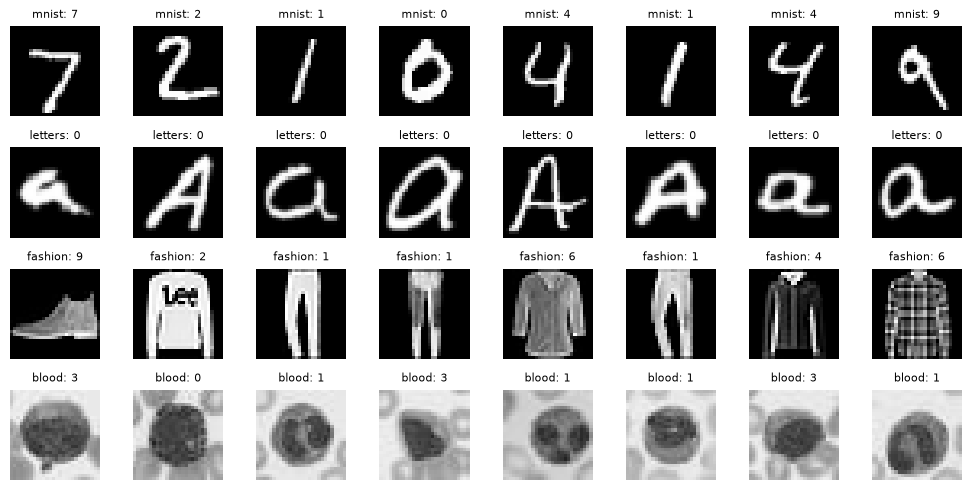

In [2]:
def load_images(name, split):
    path = CACHE / f'{name}_{split}.npz'
    if not path.exists():
        raise FileNotFoundError(f'Missing project cache: {path}')
    with np.load(path, allow_pickle=False) as data:
        images, labels = data['X'].copy(), data['y'].astype(np.int64).reshape(-1)
    assert images.shape == (len(labels), 28, 28)
    assert images.dtype == np.uint8
    if name == 'letters':
        images = images.transpose(0, 2, 1)
        assert set(np.unique(labels)) == set(range(26)), 'Expected cached zero-based letter labels'
    return np.ascontiguousarray(images), labels

raw = {(name, split): load_images(name, split)
       for name, splits in [('mnist', ['train', 'test']), ('letters', ['train', 'test']),
                            ('fashion', ['test']), ('blood', ['test'])] for split in splits}
display(pd.DataFrame([dict(dataset=name, split=split, rows=len(y), classes=len(np.unique(y)))
                      for (name, split), (images, y) in raw.items()]))
fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for row, name in enumerate(['mnist', 'letters', 'fashion', 'blood']):
    images, labels = raw[name, 'test']
    for j, ax in enumerate(axes[row]):
        ax.imshow(images[j], cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'{name}: {labels[j]}', fontsize=8)
        ax.axis('off')
plt.tight_layout()

## 2. Make disjoint training, calibration and evaluation pools

The saved encoder was fitted on the first 30,000 rows of `default_rng(0).permutation(60000)` in the MNIST training split. We reproduce that exact allocation and exclude those images from both head fitting and calibration. The next 10,000 images supply calibration; the last 20,000 supply head training. Official test splits supply evaluation only. EMNIST exposure uses its official training split.

Sampling is stratified with explicit per-class caps. Reported rates describe these sampled pools, rather than natural deployment prevalence. Every selected source index is retained in `assignments`.

In [3]:
rng = np.random.default_rng(SEED)
def stratified(labels, eligible, cap):
    selected = []
    for label in np.unique(labels[eligible]):
        ids = rng.permutation(eligible[labels[eligible] == label])
        selected.extend(ids if cap is None else ids[:cap])
    return np.asarray(selected, dtype=np.int64)

mnist_y = raw['mnist', 'train'][1]
assert len(mnist_y) == 60000, 'Saved encoder provenance expects 60,000 MNIST training images'
encoder_order = np.random.default_rng(0).permutation(len(mnist_y))
encoder_fit = encoder_order[:30000]
train_ids = stratified(mnist_y, encoder_order[40000:], DIGIT_TRAIN_PER_CLASS)
cal_ids = stratified(mnist_y, encoder_order[30000:40000], CAL_PER_CLASS)
assert not (set(encoder_fit) & set(train_ids) or set(encoder_fit) & set(cal_ids) or set(train_ids) & set(cal_ids))
letter_y = raw['letters', 'train'][1]
letter_ids = stratified(letter_y, np.arange(len(letter_y)), LETTER_TRAIN_PER_CLASS)
pools = {'train_mnist': ('mnist', 'train', train_ids),
         'train_letters': ('letters', 'train', letter_ids),
         'cal_mnist': ('mnist', 'train', cal_ids)}
for name in ['mnist', 'letters', 'fashion', 'blood']:
    labels = raw[name, 'test'][1]
    pools['test_' + name] = (name, 'test', stratified(labels, np.arange(len(labels)), EVAL_PER_CLASS))
assignments = pd.DataFrame([dict(pool=pool, dataset=name, split=split, index=int(i),
                                label=int(raw[name, split][1][i]))
                           for pool, (name, split, ids) in pools.items() for i in ids])
assert not assignments.duplicated(['dataset', 'split', 'index']).any()
display(assignments.groupby(['pool', 'dataset', 'split']).size().rename('rows').to_frame())

,,,rows
pool,dataset,split,
cal_mnist,mnist,train,2000
test_blood,blood,test,1600
test_fashion,fashion,test,2000
test_letters,letters,test,5200
test_mnist,mnist,test,2000
train_letters,letters,train,5200
train_mnist,mnist,train,10000


## 3. Extract frozen features

This is the same 64-dimensional `DigitNet` architecture and checkpoint used by the earlier MNIST REACH experiment. The encoder is frozen and deterministic. Optional L2 normalization is applied per image, without estimating statistics from test data. The encoder has seen all digit classes, but no letters, fashion, or blood images during fitting. Comparisons with the original CLIP/CIFAR experiment also change the representation and must be interpreted accordingly.

In [4]:
class DigitNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                  nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten())
        self.emb = nn.Sequential(nn.Linear(32*7*7, 64), nn.ReLU())
        self.output = nn.Linear(64, 10)
    def features(self, x):
        return self.emb(self.conv(x))
    def forward(self, x):
        return self.output(self.features(x))

encoder = DigitNet()
encoder.load_state_dict(torch.load(CHECKPOINT, map_location='cpu', weights_only=True))
encoder.eval().requires_grad_(False)

def encode(images):
    batches = []
    with torch.no_grad():
        for start in range(0, len(images), BATCH_SIZE):
            x = torch.from_numpy(images[start:start+BATCH_SIZE].copy()).float()[:, None] / 255.
            f = encoder.features(x)
            if NORMALIZE_FEATURES:
                f = nn.functional.normalize(f, dim=1)
            batches.append(f)
    return torch.cat(batches)

features = {}
for pool, (name, split, ids) in pools.items():
    features[pool] = encode(raw[name, split][0][ids])
    assert torch.isfinite(features[pool]).all()
    print(pool, tuple(features[pool].shape), 'mean norm:', round(features[pool].norm(dim=1).mean().item(), 4))

train_mnist (10000, 64) mean norm: 1.0
train_letters (5200, 64) mean norm: 1.0
cal_mnist (2000, 64) mean norm: 1.0
test_mnist (2000, 64) mean norm: 1.0
test_letters (5200, 64) mean norm: 1.0
test_fashion (2000, 64) mean norm: 1.0
test_blood (1600, 64) mean norm: 1.0


## 4. Fit an eleven-output dropout head

Outputs 0–9 are MNIST digits; output 10 is the learned unknown class. This preserves the original Linear–ReLU–Dropout–Linear head and Adam optimizer. Training uses digit labels and maps all exposed letters to unknown. Neither Fashion nor Blood enters the optimizer. Training accuracy alone is not evidence of useful uncertainty.

epoch   1: loss 2.1928
epoch  10: loss 0.5122
epoch  20: loss 0.3952
epoch  30: loss 0.3529
epoch  40: loss 0.3277
epoch  50: loss 0.3088
epoch  60: loss 0.2995
epoch  70: loss 0.2897
epoch  80: loss 0.2870
epoch  90: loss 0.2751
epoch 100: loss 0.2670
Training accuracy: 0.9170394539833069


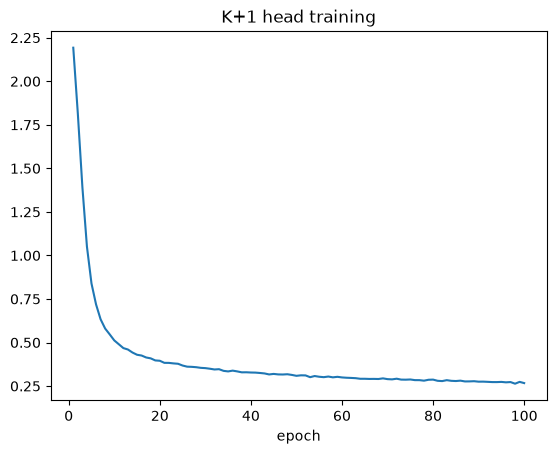

In [5]:
K = 10
class HeadDrop(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Dropout(.5), nn.Linear(128, K+1))
    def forward(self, x):
        return self.net(x)

torch.manual_seed(SEED)
train_x = torch.cat([features['train_mnist'], features['train_letters']])
train_y = torch.cat([torch.from_numpy(mnist_y[train_ids]), torch.full((len(letter_ids),), K)])
loader = DataLoader(TensorDataset(train_x, train_y), batch_size=BATCH_SIZE, shuffle=True,
                    generator=torch.Generator().manual_seed(SEED))
head = HeadDrop()
optimizer = torch.optim.Adam(head.parameters(), lr=1e-3)
history = []
for epoch in range(1, EPOCHS+1):
    head.train()
    total = 0.
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = nn.functional.cross_entropy(head(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
    history.append(dict(epoch=epoch, loss=total / len(train_y)))
    if epoch == 1 or epoch % 10 == 0:
        print(f'epoch {epoch:3d}: loss {history[-1]["loss"]:.4f}')
head.eval()
with torch.no_grad():
    print('Training accuracy:', (head(train_x).argmax(1) == train_y).float().mean().item())
pd.DataFrame(history).plot(x='epoch', y='loss', title='K+1 head training', legend=False)
plt.show()

## 5. Calibrate confidence and EU thresholds on MNIST validation only

MC dropout activates dropout while leaving the rest of the model in evaluation mode. TU = entropy of the mean prediction; AU = mean pass entropy; EU = TU − AU. We use the validation 90th percentiles of TU and EU, exactly as in the original notebook. No OOD labels or test scores tune these cutoffs.

In [6]:
def score_features(x):
    chunks = []
    for start in range(0, len(x), BATCH_SIZE):
        p = mc_probs(head, x[start:start+BATCH_SIZE], T=MC_PASSES)
        mean = p.mean(0)
        scores = uncertainty(p)
        scores.update(p_unknown=mean[:, K], prediction=mean.argmax(1))
        chunks.append(pd.DataFrame(scores))
    return pd.concat(chunks, ignore_index=True)

torch.manual_seed(SEED + 100)
calibration = score_features(features['cal_mnist'])
q_tu, q_eu = calibration['tu'].quantile(.9), calibration['eu'].quantile(.9)
print(f'MNIST validation thresholds: TU q90={q_tu:.6f}; EU q90={q_eu:.6f}')
print('Calibration digit accuracy:', (calibration.prediction.to_numpy() == mnist_y[cal_ids]).mean())

MNIST validation thresholds: TU q90=0.744021; EU q90=0.122781
Calibration digit accuracy: 0.929


## 6. Evaluate each dataset separately

For MNIST, digit accuracy includes unknown predictions as mistakes. For letters, unknown prediction is correct for the trained K+1 task. For Fashion/Blood, unknown prediction is desired rejection. A confident, low-EU recognized-digit prediction on either unseen dataset is a missed warning under these fixed thresholds.

In [7]:
torch.manual_seed(SEED + 200)
frames = []
roles = dict(mnist='KKC', letters='KUC', fashion='UUC', blood='UUC')
for name, role in roles.items():
    pool = 'test_' + name
    _, split, ids = pools[pool]
    frame = score_features(features[pool])
    frame['dataset'], frame['role'] = name, role
    frame['index'], frame['label'] = ids, raw[name, split][1][ids]
    frame['warning'] = (frame.tu <= q_tu) & (frame.eu > q_eu)
    frame['low_tu_low_eu'] = (frame.tu <= q_tu) & (frame.eu <= q_eu)
    frame['predicted_known'] = frame.prediction < K
    frame['missed_warning'] = frame.low_tu_low_eu & frame.predicted_known
    frame['task_correct'] = frame.prediction == (frame.label if name == 'mnist' else K)
    frames.append(frame)
results = pd.concat(frames, ignore_index=True)
summary = results.groupby(['dataset', 'role']).agg(
    n=('tu', 'size'), task_accuracy=('task_correct', 'mean'),
    mean_TU=('tu', 'mean'), mean_AU=('au', 'mean'), mean_EU=('eu', 'mean'),
    mean_P_unknown=('p_unknown', 'mean'), warning_rate=('warning', 'mean'),
    low_TU_low_EU_rate=('low_tu_low_eu', 'mean'),
    low_TU_low_EU_known_prediction_rate=('missed_warning', 'mean'))
display(summary.round(4))
print('The last column is a missed-warning rate for OOD; for MNIST it can include correct predictions.')

,,n,task_accuracy,mean_TU,mean_AU,mean_EU,mean_P_unknown,warning_rate,low_TU_low_EU_rate,low_TU_low_EU_known_prediction_rate
dataset,role,,,,,,,,,
blood,UUC,1600,1.0000,0.0257,0.0190,0.0067,0.9961,0.0000,1.0000,0.0000
fashion,UUC,2000,0.9580,0.3229,0.2696,0.0533,0.8776,0.0160,0.8120,0.0135
letters,KUC,5200,0.8750,0.3800,0.3133,0.0668,0.8125,0.0538,0.8052,0.0854
mnist,KKC,2000,0.9435,0.3467,0.2966,0.0501,0.0965,0.0195,0.8820,0.8635


The last column is a missed-warning rate for OOD; for MNIST it can include correct predictions.


## 7. Compare detection scores against MNIST

Each comparison uses MNIST negatives and just one other dataset as positives. Higher scores mean more outlier-like. KUC (EMNIST) is explicitly separated from UUC; pooling them would obscure the effect of outlier exposure. AUROC is threshold-free; FPR@95TPR uses the first empirical ROC point achieving 95% TPR. These are single-fit point estimates, not confidence intervals.

,dataset,role,score,auroc,fpr95
0,letters,KUC,eu,0.5935,0.9985
1,letters,KUC,tu,0.5127,1.0000
2,letters,KUC,au,0.4961,1.0000
3,letters,KUC,p_unknown,0.9793,0.1205
4,fashion,UUC,eu,0.4446,1.0000
5,fashion,UUC,tu,0.3786,1.0000
6,fashion,UUC,au,0.3703,1.0000
7,fashion,UUC,p_unknown,0.9890,0.0440
8,blood,UUC,eu,0.0708,1.0000
9,blood,UUC,tu,0.0157,1.0000


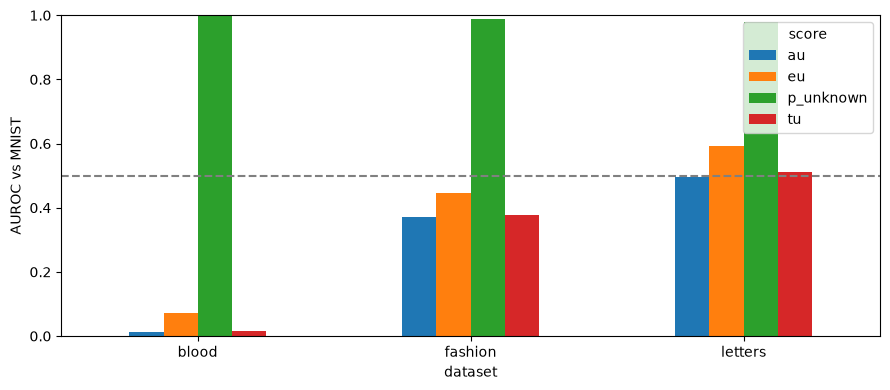

In [8]:
detection_rows = []
known = results[results.dataset == 'mnist']
for name in ['letters', 'fashion', 'blood']:
    other = results[results.dataset == name]
    target = np.r_[np.zeros(len(known)), np.ones(len(other))]
    for score in ['eu', 'tu', 'au', 'p_unknown']:
        values = np.r_[known[score], other[score]]
        fpr, tpr, _ = roc_curve(target, values)
        detection_rows.append(dict(dataset=name, role=roles[name], score=score,
                                   auroc=roc_auc_score(target, values),
                                   fpr95=fpr[np.flatnonzero(tpr >= .95)[0]]))
detection = pd.DataFrame(detection_rows)
display(detection.round(4))
detection.pivot(index='dataset', columns='score', values='auroc').plot.bar(
    ylim=(0, 1), rot=0, ylabel='AUROC vs MNIST', figsize=(9, 4))
plt.axhline(.5, color='gray', ls='--')
plt.tight_layout()
plt.show()

## 8. Inspect the uncertainty quadrants and actual missed examples

Shared axes allow comparisons across datasets. The lower-left quadrant has low TU and low EU; the upper-left has low TU and high EU. Neither intersection has a predetermined 10% rate. Image examples below are selected by the fixed thresholds, so they illustrate failure cases rather than their prevalence.

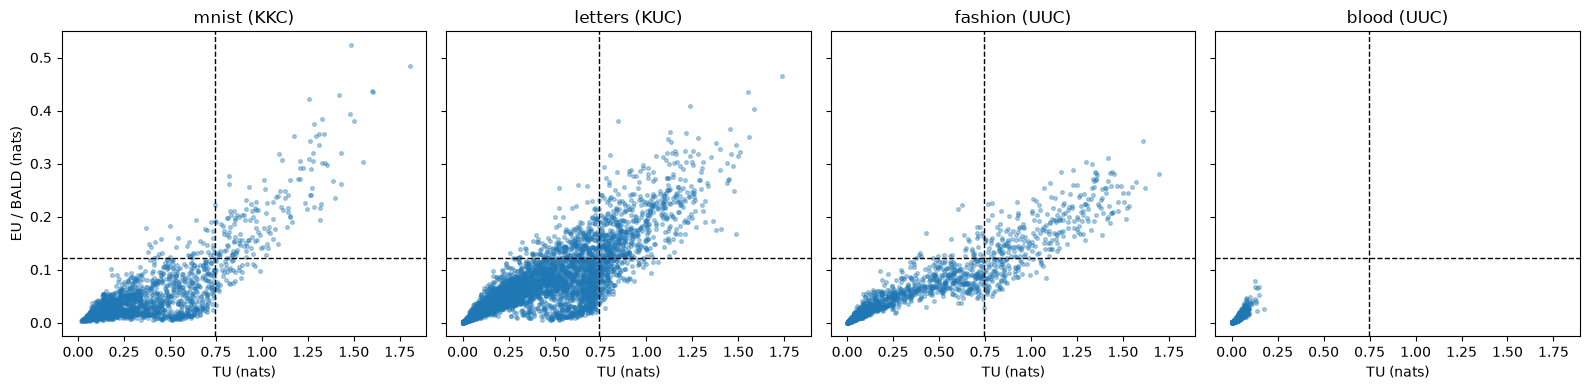

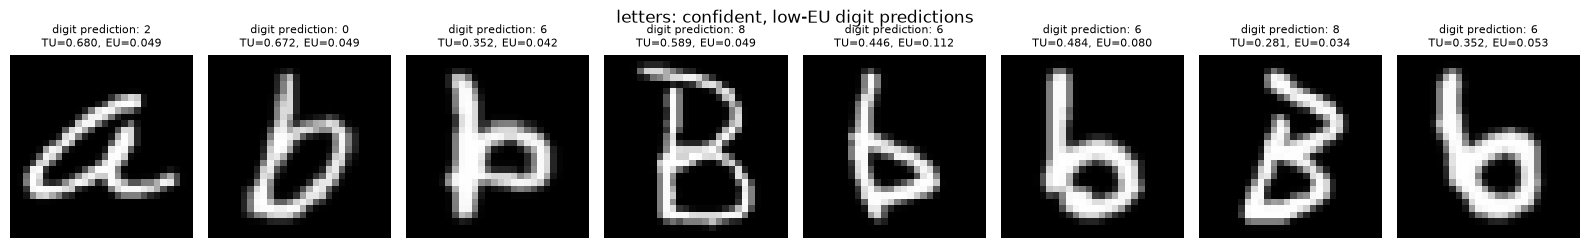

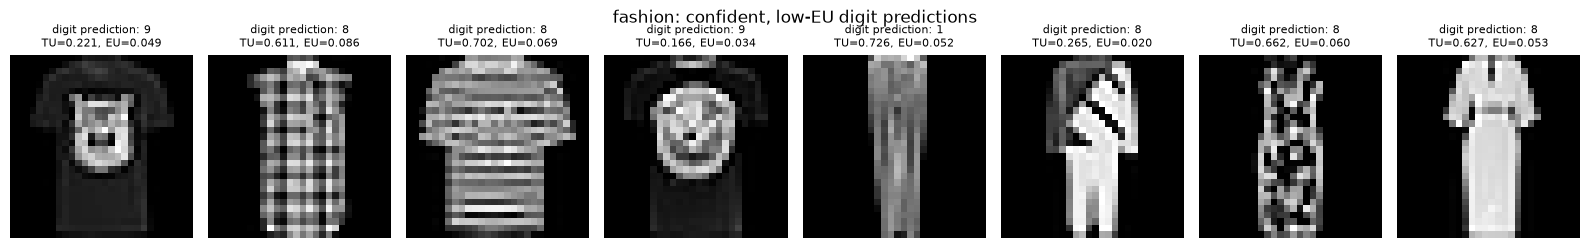

blood : no missed-warning examples under these thresholds


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
for ax, name in zip(axes, roles):
    frame = results[results.dataset == name]
    ax.scatter(frame.tu, frame.eu, s=7, alpha=.35)
    ax.axvline(q_tu, color='black', ls='--', lw=1)
    ax.axhline(q_eu, color='black', ls='--', lw=1)
    ax.set(title=f'{name} ({roles[name]})', xlabel='TU (nats)')
axes[0].set_ylabel('EU / BALD (nats)')
plt.tight_layout()
plt.show()

for name in ['letters', 'fashion', 'blood']:
    examples = results[(results.dataset == name) & results.missed_warning].head(8)
    if examples.empty:
        print(name, ': no missed-warning examples under these thresholds')
        continue
    fig, axes = plt.subplots(1, len(examples), figsize=(2*len(examples), 2.5), squeeze=False)
    for ax, (_, row) in zip(axes[0], examples.iterrows()):
        ax.imshow(raw[name, 'test'][0][int(row['index'])], cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'digit prediction: {int(row.prediction)}\nTU={row.tu:.3f}, EU={row.eu:.3f}', fontsize=8)
        ax.axis('off')
    fig.suptitle(f'{name}: confident, low-EU digit predictions')
    plt.tight_layout()
    plt.show()

## 9. Optional: save this run

Set `SAVE_RESULTS=True` to export the configuration, exact row assignments, per-image scores, summary tables and fitted head. Use a fresh directory for each experiment so settings and outputs stay paired.

In [10]:
SAVE_RESULTS = False
OUTPUT = ROOT / 'workbook/eu_blindspot_four_datasets_seed0'
if SAVE_RESULTS:
    import json
    import hashlib
    OUTPUT.mkdir(parents=True, exist_ok=False)
    config = dict(seed=SEED, epochs=EPOCHS, mc_passes=MC_PASSES,
                  digit_train_per_class=DIGIT_TRAIN_PER_CLASS, letter_train_per_class=LETTER_TRAIN_PER_CLASS,
                  eval_per_class=EVAL_PER_CLASS, cal_per_class=CAL_PER_CLASS,
                  normalized_features=NORMALIZE_FEATURES, roles=roles,
                  checkpoint=str(CHECKPOINT.relative_to(ROOT)),
                  checkpoint_sha256=hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest(),
                  q_tu=float(q_tu), q_eu=float(q_eu), torch_version=str(torch.__version__))
    (OUTPUT / 'config.json').write_text(json.dumps(config, indent=2))
    assignments.to_csv(OUTPUT / 'assignments.csv', index=False)
    results.to_csv(OUTPUT / 'scores.csv', index=False)
    summary.to_csv(OUTPUT / 'summary.csv')
    detection.to_csv(OUTPUT / 'detection.csv', index=False)
    pd.DataFrame(history).to_csv(OUTPUT / 'training.csv', index=False)
    torch.save(head.state_dict(), OUTPUT / 'head.pt')
    print('Saved:', OUTPUT)

## Interpretation and next experiments

Check MNIST test accuracy before interpreting uncertainty. Compare EU with TU and the learned unknown probability separately for Fashion and Blood. Inspect the low-TU/low-EU known-prediction rate: low EU does not certify support, and a high AUROC can coexist with confident errors.

EMNIST has been exposed during head fitting. To study **unseen EMNIST**, a separate experiment must withhold letter classes or remove letter exposure; this notebook does not claim that result. Blood uses grayscale input through a digit encoder, which is a substantial representation mismatch. Repeat seeds and vary outlier exposure before generalizing. This notebook covers the core dataset/uncertainty analysis; the original notebook's feature attacks and architecture sweeps remain separate.